# Recuperação de Informação: TF-IDF × BM25 no acervo de uma biblioteca

**Projeto 2: Estatística e Probabilidade para Computação (CIn-UFPE, 2026.2)**

**Equipe:** Arthur Dias, Eduardo Henrique, Felipe Augusto, Gabriel André e Philip Santiago.

Repositório: https://github.com/philipsantiagoo/acervo-rank

## 0. Configuração

Instalação e carregamento dos pacotes, e endereço dos dados no GitHub.

In [ ]:
# Pacotes usados na análise (conforme lista oficial no README.md)
pacotes <- c("ggplot2", "dplyr", "tidyr", "stopwords", "SnowballC")

# Instala apenas os pacotes que ainda não estão disponíveis no ambiente
pacotes_faltantes <- pacotes[!vapply(pacotes, requireNamespace, logical(1), quietly = TRUE)]
if (length(pacotes_faltantes) > 0) {
  install.packages(pacotes_faltantes, repos = "https://cloud.r-project.org")
}

# Carrega os pacotes sem poluir a saída do notebook
invisible(lapply(pacotes, function(p) {
  suppressPackageStartupMessages(library(p, character.only = TRUE))
}))

# Endereço dos dados do CISI no repositório do projeto
url_dados <- "https://raw.githubusercontent.com/philipsantiagoo/acervo-rank/main/data/raw/"

# Opções globais portáveis (Windows, Linux, macOS e Colab)
options(
  encoding = "UTF-8",
  scipen = 999,
  repr.plot.width = 9,
  repr.plot.height = 5
)

# Paleta e tema padrão para manter consistência visual em todos os gráficos
CORES_PROJETO <- c(
  principal  = "#2C5F8A",
  destaque   = "#D95F02",
  secundario = "#1B9E77",
  neutro     = "#7F8C8D"
)

theme_set(
  theme_minimal(base_size = 12) +
    theme(
      plot.title = element_text(face = "bold"),
      plot.subtitle = element_text(color = "#555555"),
      legend.position = "bottom"
    )
)

## 1. Introdução

### 1.1. Contextualização

Uma biblioteca universitária quer melhorar a busca do seu acervo de artigos. Hoje, o sistema ordena os resultados com **TF-IDF**, um modelo vetorial que dá peso às palavras conforme a frequência delas no documento e a raridade na coleção. A proposta é trocar pelo **BM25**, um modelo probabilístico que é o padrão em motores de busca como Lucene e Elasticsearch.

O BM25 corrige dois defeitos conhecidos do TF-IDF:

- **saturação:** repetir uma palavra muitas vezes não aumenta a nota sem limite;
- **normalização pelo tamanho:** documentos longos não ganham pontos só por serem longos.

Trocar de sistema tem custo. Por isso, a biblioteca só quer fazer a troca se houver **evidência estatística** de que os usuários seriam mais bem atendidos. Este projeto dá continuidade ao plano apresentado no Projeto 1.


### 1.2. Objetivo

**Pergunta central:** com o BM25, os pesquisadores encontram os artigos certos mais perto do topo da lista do que com o TF-IDF, e essa melhora é estatisticamente significativa?

Para responder, vamos:

1. explorar a coleção e testar se o **tamanho dos artigos** está relacionado à relevância, o que justificaria a normalização feita pelo BM25 (seção 3);
2. implementar os dois modelos e ordenar todos os artigos para cada consulta (seção 4);
3. medir a qualidade de cada ranking com **P@10, MAP e nDCG@10** e comparar os modelos consulta a consulta com um **teste t pareado unilateral** (α = 0,05) (seção 5).

**Hipótese (Projeto 1):** com o BM25, os pesquisadores verão mais artigos relevantes no topo da busca do que com o TF-IDF, porque ele não supervaloriza termos repetidos nem documentos longos.


### 1.3. Descrição dos Dados

Um acervo real não tem gabarito: não se sabe quais artigos respondem cada pergunta. Por isso, a coleção **CISI** faz o papel do acervo da biblioteca. É uma coleção de teste clássica de Recuperação de Informação, distribuída pela Universidade de Glasgow (https://ir.dcs.gla.ac.uk/resources/test_collections/cisi/), com resumos de artigos de ciência da informação, consultas de pesquisadores e julgamentos de relevância feitos por pessoas.

São três arquivos de texto, salvos no repositório do projeto:

| Arquivo | Conteúdo |
| --- | --- |
| `CISI.ALL` | 1.460 artigos: título, autores, resumo e referências cruzadas |
| `CISI.QRY` | 112 consultas |
| `CISI.REL` | Gabarito: pares (consulta, artigo relevante) |

Nos arquivos `.ALL` e `.QRY`, cada campo começa com um marcador no início da linha (`.I` identificador, `.T` título, `.A` autores, `.W` texto, `.X` referências, `.B` ano ou fonte) e pode ocupar várias linhas.

**Dicionário de dados** (tabelas montadas na seção 2.1):

**`artigos`**: um artigo por linha.

| Coluna | Tipo | Descrição |
| --- | --- | --- |
| `doc_id` | inteiro | Identificador do artigo (1 a 1.460) |
| `titulo` | texto | Título do artigo (campo `.T`) |
| `resumo` | texto | Resumo do artigo (campo `.W`) |
| `texto` | texto | Título + resumo: o texto que os modelos vão usar |

**`consultas`**: uma consulta por linha.

| Coluna | Tipo | Descrição |
| --- | --- | --- |
| `query_id` | inteiro | Identificador da consulta (1 a 112) |
| `texto` | texto | Texto da consulta (campo `.W`) |
| `tipo` | texto | `"pergunta"` (escrita por um pesquisador) ou `"artigo"` (resumo de um artigo usado como consulta) |
| `tem_gabarito` | lógico | Se a consulta tem pelo menos um artigo relevante no gabarito |

**`gabarito`**: um par relevante por linha.

| Coluna | Tipo | Descrição |
| --- | --- | --- |
| `query_id` | inteiro | Identificador da consulta |
| `doc_id` | inteiro | Identificador de um artigo relevante para essa consulta |

A relevância é **binária**: se um par (consulta, artigo) não está no gabarito, o artigo não é relevante para a consulta.


## 2. Análise Exploratória de Dados (EDA)

### 2.1. Carregamento e Limpeza dos Dados

Os arquivos são lidos direto do GitHub, para o notebook funcionar em qualquer máquina. Como o formato do CISI é baseado em marcadores, e não em colunas, escrevemos funções próprias de leitura.

Ao inspecionar os arquivos, encontramos alguns detalhes que a leitura precisa tratar:

- **Quebra de linha do Windows:** todas as linhas terminam com `\r\n`. O `\r` é removido.
- **Marcadores não documentados:** além de `.T`, `.A`, `.W` e `.X`, o `CISI.ALL` tem `.B` (ano de publicação, em 24 artigos), `.K` (palavras-chave) e `.C` (códigos de classificação), esses dois só no artigo 321. Por isso, **qualquer** marcador encerra o campo anterior. Se só os conhecidos fossem reconhecidos, as palavras-chave do artigo 321 entrariam no resumo dele.
- **Espaço depois do marcador:** em 15 linhas, o marcador aparece como `.T ` em vez de `.T`.
- **Linhas em branco** no meio dos textos (43 no `CISI.ALL`), que são descartadas.
- **Campos em várias linhas:** as linhas de um mesmo campo são unidas com espaço, e espaços repetidos são reduzidos a um.


In [ ]:
# Lê um arquivo do CISI direto do GitHub.
# Entrada: nome do arquivo (ex.: "CISI.ALL"). Saída: vetor de linhas, sem o "\r" do fim.
ler_linhas <- function(arquivo) {
  con <- url(paste0(url_dados, arquivo))
  linhas <- readLines(con, warn = FALSE, encoding = "UTF-8")
  close(con)
  sub("\r$", "", linhas)
}

# Junta espaços repetidos (inclusive quebras e tabulações) e tira os das pontas.
# Entrada: vetor de textos. Saída: vetor de textos limpos.
limpar <- function(x) trimws(gsub("\\s+", " ", x))

# Separa as linhas de CISI.ALL ou CISI.QRY em registros e campos.
# Entrada: vetor de linhas. Saída: data frame com uma linha por registro, a coluna
# `id` e uma coluna por marcador encontrado (T, A, W, X, ...), com o texto do campo.
ler_registros <- function(linhas) {
  eh_id       <- grepl("^\\.I\\s+[0-9]+\\s*$", linhas)
  eh_marcador <- eh_id | grepl("^\\.[A-Z]\\s*$", linhas)   # aceita espaço depois do marcador
  registro    <- cumsum(eh_id)                              # a qual registro cada linha pertence
  campo       <- ifelse(eh_marcador, substr(linhas, 2, 2), NA)
  ultimo      <- cummax(ifelse(eh_marcador, seq_along(linhas), 0L))
  campo_atual <- c(NA, campo)[ultimo + 1]                   # último marcador visto até a linha
  conteudo    <- !eh_marcador & trimws(linhas) != ""        # descarta marcadores e linhas em branco

  textos <- tapply(linhas[conteudo],
                   list(registro[conteudo], campo_atual[conteudo]),
                   paste, collapse = " ")
  tabela <- as.data.frame(textos, stringsAsFactors = FALSE)
  ids <- as.integer(sub("^\\.I\\s+", "", linhas[eh_id]))
  tabela$id <- ids[as.integer(rownames(textos))]
  rownames(tabela) <- NULL
  tabela
}


**Artigos.** Cada artigo vira uma linha. O texto que os modelos vão usar é **título + resumo**: são os campos que dizem do que o artigo trata. Autores, ano, referências cruzadas e palavras-chave ficam de fora.


In [ ]:
registros_all <- ler_registros(ler_linhas("CISI.ALL"))

artigos <- data.frame(
  doc_id = registros_all$id,
  titulo = limpar(registros_all$T),
  resumo = limpar(registros_all$W)
)
artigos$texto <- paste(artigos$titulo, artigos$resumo)

head(artigos[, c("doc_id", "titulo")])


,doc_id,titulo
,<int>,<chr>
1,1,18 Editions of the Dewey Decimal Classifications
2,2,Use Made of Technical Libraries
3,3,Two Kinds of Power An Essay on Bibliographic Control
4,4,Systems Analysis of a University Library; final report and research project
5,5,A Library Management Game: a report on a research project
6,6,Abstracting Concepts and Methods


**Consultas.** Usamos o campo `.W` de cada consulta. Ao ler o arquivo, notamos que existem **dois tipos de consulta**: perguntas escritas por pesquisadores (só `.W`) e resumos de artigos usados como consulta (com `.T`, `.A` e `.B`, além do `.W`). Guardamos o tipo na coluna `tipo` para analisar na EDA.


In [ ]:
registros_qry <- ler_registros(ler_linhas("CISI.QRY"))

consultas <- data.frame(
  query_id = registros_qry$id,
  texto    = limpar(registros_qry$W),
  tipo     = ifelse(is.na(registros_qry$T), "pergunta", "artigo")
)

head(consultas)


,query_id,texto,tipo
,<int>,<chr>,<chr>
1,1,What problems and concerns are there in making up descriptive titles? What difficulties are involved in automatically retrieving articles from approximate titles? What is the usual relevance of the content of articles to their titles?,pergunta
2,2,"How can actually pertinent data, as opposed to references or entire articles themselves, be retrieved automatically in response to information requests?",pergunta
3,3,What is information science? Give definitions where possible.,pergunta
4,4,Image recognition and any other methods of automatically transforming printed text into computer-ready form.,pergunta
5,5,What special training will ordinary researchers and businessmen need for proper information management and unobstructed use of information retrieval systems? What problems are they likely to encounter?,pergunta
6,6,"What possibilities are there for verbal communication between computers and humans, that is, communication via the spoken word?",pergunta


**Gabarito.** O `CISI.REL` tem quatro colunas: consulta, artigo relevante e duas colunas sem uso (sempre `0` e `0.000000`), que descartamos.


In [ ]:
gabarito <- read.table(text = ler_linhas("CISI.REL"),
                       col.names = c("query_id", "doc_id", "nao_usada_1", "nao_usada_2"))
gabarito <- gabarito[, c("query_id", "doc_id")]

consultas$tem_gabarito <- consultas$query_id %in% gabarito$query_id

head(gabarito)


,query_id,doc_id
,<int>,<int>
1,1,28
2,1,35
3,1,38
4,1,42
5,1,43
6,1,52


**Estrutura das tabelas.** Tipos de cada coluna e resumo numérico do gabarito.


In [ ]:
str(artigos)
str(consultas)
str(gabarito)
summary(gabarito)


'data.frame':	1460 obs. of  4 variables:
 $ doc_id: int  1 2 3 4 5 6 7 8 9 10 ...
 $ titulo: chr  "18 Editions of the Dewey Decimal Classifications" "Use Made of Technical Libraries" "Two Kinds of Power An Essay on Bibliographic Control" "Systems Analysis of a University Library; final report and research project" ...
 $ resumo: chr  "The present study is a history of the DEWEY Decimal Classification. The first edition of the DDC was published "| __truncated__ "This report is an analysis of 6300 acts of use in 104 technical libraries in the United Kingdom. Library use is"| __truncated__ "The relationships between the organization and control of writings and the organization and control of knowledg"| __truncated__ "The establishment of nine new universities in the 1960's provoked a highly stimulating re-examination of the na"| __truncated__ ...
 $ texto : chr  "18 Editions of the Dewey Decimal Classifications The present study is a history of the DEWEY Decimal Classifica"| __truncated__

    query_id          doc_id      
 Min.   :  1.00   Min.   :   1.0  
 1st Qu.: 20.00   1st Qu.: 309.0  
 Median : 32.00   Median : 640.0  
 Mean   : 39.87   Mean   : 656.7  
 3rd Qu.: 50.00   3rd Qu.: 990.8  
 Max.   :111.00   Max.   :1460.0  

**Valores faltantes e duplicados.** Conferimos valores `NA`, textos vazios, identificadores repetidos e pares repetidos no gabarito.


In [ ]:
faltantes <- data.frame(
  tabela = c("artigos", "consultas", "gabarito"),
  valores_NA = c(sum(is.na(artigos)), sum(is.na(consultas)), sum(is.na(gabarito))),
  textos_vazios = c(sum(artigos$titulo == "" | artigos$resumo == ""), sum(consultas$texto == ""), NA),
  ids_duplicados = c(sum(duplicated(artigos$doc_id)), sum(duplicated(consultas$query_id)), NA),
  pares_duplicados = c(NA, NA, sum(duplicated(gabarito)))
)
faltantes


tabela,valores_NA,textos_vazios,ids_duplicados,pares_duplicados
<chr>,<int>,<int>,<int>,<int>
artigos,0,0,0,NA
consultas,0,0,0,NA
gabarito,0,NA,NA,0


**Conferência.** Comparamos as contagens com os valores esperados da coleção. Se alguma não bater, a célula para com erro.


In [ ]:
conferencia <- data.frame(
  verificacao = c("Artigos", "Consultas", "Consultas com gabarito", "Pares no gabarito",
                  "Consultas do tipo artigo", "Consultas do tipo artigo com gabarito",
                  "Gabarito aponta para artigos existentes",
                  "Palavras-chave do artigo 321 fora do resumo"),
  esperado = c(1460, 112, 76, 3114, 55, 26, TRUE, TRUE),
  obtido = c(nrow(artigos), nrow(consultas), sum(consultas$tem_gabarito), nrow(gabarito),
             sum(consultas$tipo == "artigo"),
             sum(consultas$tipo == "artigo" & consultas$tem_gabarito),
             all(gabarito$doc_id %in% artigos$doc_id),
             !grepl("text searching", artigos$resumo[artigos$doc_id == 321]))
)
conferencia$ok <- conferencia$esperado == conferencia$obtido

# As duas últimas verificações são lógicas: mostra "sim"/"não" em vez de 1/0
verificacoes_logicas <- 7:8
conferencia$esperado <- as.character(conferencia$esperado)
conferencia$obtido   <- as.character(conferencia$obtido)
conferencia$esperado[verificacoes_logicas] <- "sim"
conferencia$obtido[verificacoes_logicas]   <- ifelse(conferencia$ok[verificacoes_logicas], "sim", "não")
conferencia
stopifnot(all(conferencia$ok))


verificacao,esperado,obtido,ok
<chr>,<dbl>,<int>,<lgl>
Artigos,1460,1460,TRUE
Consultas,112,112,TRUE
Consultas com gabarito,76,76,TRUE
Pares no gabarito,3114,3114,TRUE
Consultas do tipo artigo,55,55,TRUE
Consultas do tipo artigo com gabarito,26,26,TRUE
Gabarito aponta para artigos existentes,1,1,TRUE
Palavras-chave do artigo 321 fora do resumo,1,1,TRUE


**Consultas com e sem gabarito, por tipo.**


In [ ]:
table(tipo = consultas$tipo, tem_gabarito = consultas$tem_gabarito)


          tem_gabarito
tipo       FALSE TRUE
  artigo      29   26
  pergunta     7   50

**Resumo da limpeza:**

- Não há valores faltantes, textos vazios nem duplicados nas três tabelas.
- Todos os artigos do gabarito existem na coleção.
- **36 das 112 consultas não têm gabarito** e ficam de fora da avaliação dos modelos, porque sem gabarito não há como medir. Restam **76 consultas**.
- **Desvio em relação ao Projeto 1:** no Projeto 1, descrevemos as consultas como "escritas por pesquisadores". A leitura mostrou que 55 das 112 consultas são, na verdade, resumos de artigos usados como consulta, e 26 delas têm gabarito. Mantemos as 76 consultas com gabarito, usando o campo `.W` de todas, e comparamos os dois tipos na EDA.


### 2.2. Análise Univariada

Antes de comparar relações entre variáveis, exploramos cada variável relevante da coleção individualmente para entender sua escala, dispersão e grau de assimetria.

Para isso, calculamos variáveis derivadas diretamente sobre as tabelas montadas na seção 2.1 (sem alterar os textos originais que serão usados na modelagem):

- **Tamanho dos artigos** (`n_palavras`): contagem de palavras alfabéticas em título + resumo (`artigos$texto`), além das contagens separadas de título e resumo.
- **Tamanho das consultas** (`n_palavras`): contagem de palavras alfabéticas no campo `.W` (`consultas$texto`).
- **Contagens de relevância:** em quantas consultas cada artigo aparece como relevante (`n_consultas_relevante`) e quantos artigos relevantes cada consulta possui no gabarito (`n_relevantes`).

Em seguida, resumimos todas as variáveis numéricas com mínimo, quartis, mediana, média, desvio-padrão, intervalo interquartil (IQR) e **assimetria** (*skewness*), métrica importante para diagnosticar caudas longas e orientar a escolha do teste estatístico na seção 3.

In [ ]:
# Extrai palavras alfabéticas em minúsculas de um texto.
# Entrada: texto (string única). Saída: vetor de palavras contendo apenas letras (a-z).
extrair_palavras <- function(texto) {
  if (is.na(texto) || !nzchar(trimws(texto))) return(character(0))
  texto_min <- tolower(texto)
  regmatches(texto_min, gregexpr("[a-z]+", texto_min, perl = TRUE))[[1]]
}

# Conta o número de palavras alfabéticas de cada texto em um vetor.
# Entrada: vetor de textos. Saída: vetor inteiro com a contagem de palavras.
contar_palavras <- function(vetor_texto) {
  vapply(vetor_texto, function(t) length(extrair_palavras(t)), integer(1))
}

# Calcula o coeficiente de assimetria amostral (skewness) de um vetor numérico.
# Entrada: x (vetor numérico). Saída: valor numérico (0 = simétrico; > 0 = cauda à direita).
calcular_assimetria <- function(x) {
  x <- x[!is.na(x)]
  s <- sd(x)
  if (length(x) < 3 || is.na(s) || s == 0) return(NA_real_)
  mean(((x - mean(x)) / s)^3)
}

# Monta uma linha de estatísticas descritivas para uma variável numérica.
# Entrada: x (vetor numérico) e nome (string descritiva). Saída: data frame de 1 linha.
resumir_variavel <- function(x, nome) {
  q <- quantile(x, probs = c(0.25, 0.50, 0.75), na.rm = TRUE)
  data.frame(
    Variavel   = nome,
    N          = sum(!is.na(x)),
    Min        = min(x, na.rm = TRUE),
    Q1         = round(unname(q[1]), 1),
    Mediana    = round(unname(q[2]), 1),
    Media      = round(mean(x, na.rm = TRUE), 2),
    Q3         = round(unname(q[3]), 1),
    Max        = max(x, na.rm = TRUE),
    DP         = round(sd(x, na.rm = TRUE), 2),
    IQR        = round(IQR(x, na.rm = TRUE), 1),
    Assimetria = round(calcular_assimetria(x), 2),
    stringsAsFactors = FALSE
  )
}

# Enriquecimento idempotente da tabela `artigos` (pode reexecutar a célula sem duplicar colunas)
contagem_por_artigo <- table(gabarito$doc_id)
artigos$n_consultas_relevante <- as.integer(contagem_por_artigo[as.character(artigos$doc_id)])
artigos$n_consultas_relevante[is.na(artigos$n_consultas_relevante)] <- 0L
artigos$foi_relevante <- factor(
  ifelse(artigos$n_consultas_relevante > 0L, "Relevante", "Nunca relevante"),
  levels = c("Nunca relevante", "Relevante")
)
artigos$n_palavras_titulo <- contar_palavras(artigos$titulo)
artigos$n_palavras_resumo <- contar_palavras(artigos$resumo)
artigos$n_palavras        <- contar_palavras(artigos$texto)

# Enriquecimento idempotente da tabela `consultas` e criação do subconjunto avaliado (76 consultas)
contagem_por_consulta <- table(gabarito$query_id)
consultas$n_relevantes <- as.integer(contagem_por_consulta[as.character(consultas$query_id)])
consultas$n_relevantes[is.na(consultas$n_relevantes)] <- 0L
consultas$n_palavras <- contar_palavras(consultas$texto)

consultas_avaliadas <- consultas %>% filter(tem_gabarito)

# Tabela resumo das variáveis numéricas principais
tabela_univariada <- bind_rows(
  resumir_variavel(artigos$n_palavras,               "Tamanho dos artigos (título + resumo)"),
  resumir_variavel(artigos$n_palavras_titulo,        "Tamanho dos títulos"),
  resumir_variavel(artigos$n_palavras_resumo,        "Tamanho dos resumos"),
  resumir_variavel(consultas$n_palavras,             "Tamanho das consultas (todas, n = 112)"),
  resumir_variavel(consultas_avaliadas$n_palavras,   "Tamanho das consultas (com gabarito, n = 76)"),
  resumir_variavel(consultas_avaliadas$n_relevantes, "Artigos relevantes por consulta (n = 76)")
)
tabela_univariada

# Cobertura do acervo pelo gabarito
artigos %>%
  count(foi_relevante, name = "n_artigos") %>%
  mutate(percentual = round(100 * n_artigos / sum(n_artigos), 1))

Variavel,N,Min,Q1,Mediana,Media,Q3,Max,DP,IQR,Assimetria
<chr>,<int>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<int>,<dbl>,<dbl>,<dbl>
Tamanho dos artigos (título + resumo),1460,10,83.0,118.5,127.29,160.2,564,63.76,77.2,1.41
Tamanho dos títulos,1460,1,5.0,7.0,7.89,10.0,35,4.13,5.0,1.16
Tamanho dos resumos,1460,8,75.0,110.0,119.40,152.0,552,63.39,77.0,1.42
"Tamanho das consultas (todas, n = 112)",112,4,20.8,66.5,76.29,115.5,335,60.52,94.8,1.10
"Tamanho das consultas (com gabarito, n = 76)",76,4,13.8,49.5,59.76,87.0,335,59.02,73.2,1.83
Artigos relevantes por consulta (n = 76),76,1,13.0,30.5,40.97,52.2,155,36.17,39.2,1.37


foi_relevante,n_artigos,percentual
<fct>,<int>,<dbl>
Nunca relevante,298,20.4
Relevante,1162,79.6


**Tamanho dos artigos e das consultas.** Os histogramas abaixo mostram como o comprimento dos textos (em palavras) se distribui no acervo completo de 1.460 artigos e nas 76 consultas com gabarito. Destacamos a média e a mediana em cada gráfico para visualizar rapidamente a presença de assimetria e documentos extremos.

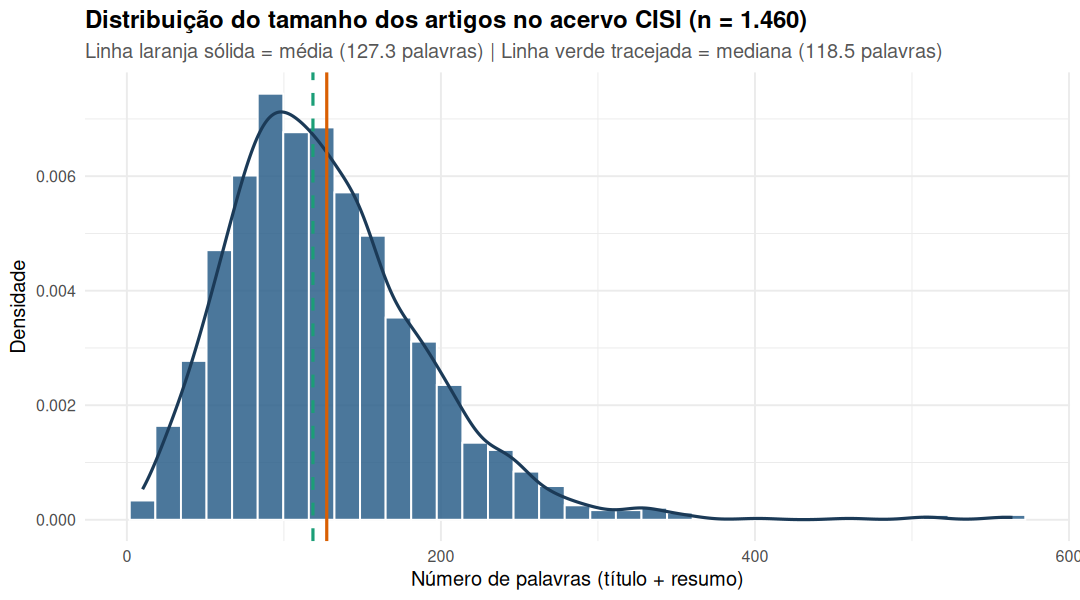

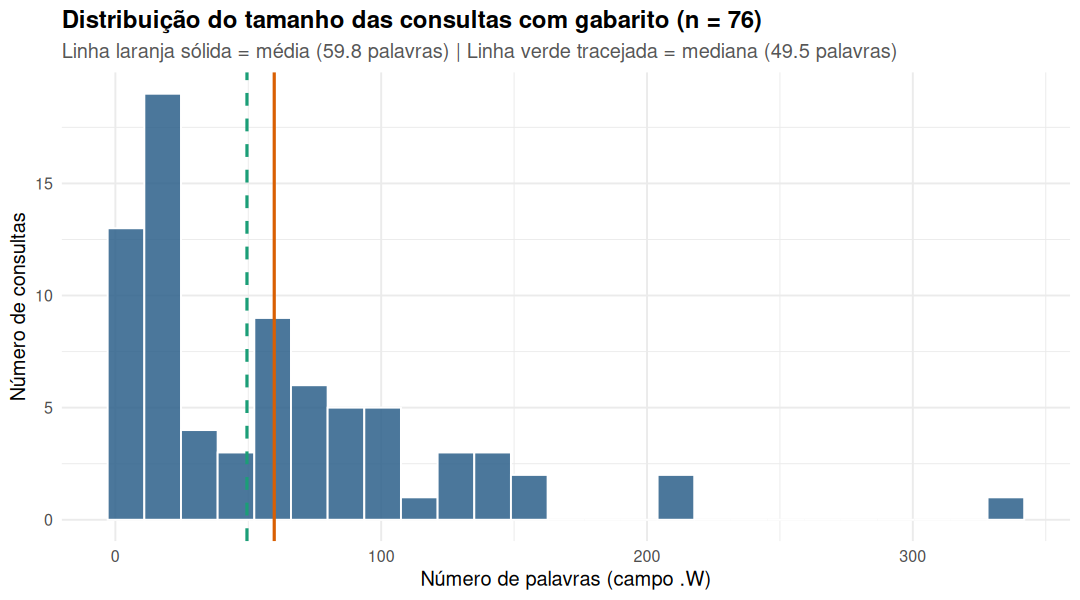

In [ ]:
# Gráfico 1: Distribuição do tamanho dos artigos (título + resumo)
media_art   <- mean(artigos$n_palavras)
mediana_art <- median(artigos$n_palavras)

g_tam_artigos <- ggplot(artigos, aes(x = n_palavras)) +
  geom_histogram(
    aes(y = after_stat(density)),
    bins = 35,
    fill = CORES_PROJETO[["principal"]],
    color = "white",
    alpha = 0.85
  ) +
  geom_density(color = "#1B3A57", linewidth = 0.9) +
  geom_vline(xintercept = mediana_art, color = CORES_PROJETO[["secundario"]], linetype = "dashed", linewidth = 0.9) +
  geom_vline(xintercept = media_art,   color = CORES_PROJETO[["destaque"]],   linetype = "solid",  linewidth = 0.9) +
  labs(
    title = "Distribuição do tamanho dos artigos no acervo CISI (n = 1.460)",
    subtitle = sprintf("Linha laranja sólida = média (%.1f palavras) | Linha verde tracejada = mediana (%.1f palavras)", media_art, mediana_art),
    x = "Número de palavras (título + resumo)",
    y = "Densidade"
  )
print(g_tam_artigos)

# Gráfico 2: Distribuição do tamanho das consultas com gabarito
media_qry   <- mean(consultas_avaliadas$n_palavras)
mediana_qry <- median(consultas_avaliadas$n_palavras)

g_tam_consultas <- ggplot(consultas_avaliadas, aes(x = n_palavras)) +
  geom_histogram(
    bins = 25,
    fill = CORES_PROJETO[["principal"]],
    color = "white",
    alpha = 0.85
  ) +
  geom_vline(xintercept = mediana_qry, color = CORES_PROJETO[["secundario"]], linetype = "dashed", linewidth = 0.9) +
  geom_vline(xintercept = media_qry,   color = CORES_PROJETO[["destaque"]],   linetype = "solid",  linewidth = 0.9) +
  labs(
    title = "Distribuição do tamanho das consultas com gabarito (n = 76)",
    subtitle = sprintf("Linha laranja sólida = média (%.1f palavras) | Linha verde tracejada = mediana (%.1f palavras)", media_qry, mediana_qry),
    x = "Número de palavras (campo .W)",
    y = "Número de consultas"
  )
print(g_tam_consultas)

**Artigos relevantes por consulta.** Aqui observamos quantos artigos do acervo são marcados como relevantes para cada uma das 76 consultas avaliadas, destacando também os extremos (consultas com mais e menos artigos relevantes no gabarito). Uma dispersão elevada nessa variável indica que as consultas têm graus de dificuldade e abrangência muito diferentes entre si.

Top 5 consultas com MAIS artigos relevantes:
  query_id     tipo n_palavras n_relevantes
1       44 pergunta         56          155
2       20 pergunta          4          144
3       30 pergunta          6          134
4       11 pergunta         13          127
5       32 pergunta         20          117

Top 5 consultas com MENOS artigos relevantes:
  query_id     tipo n_palavras n_relevantes
1        6 pergunta         18            1
2      101   artigo         96            1
3       14 pergunta          8            3
4       97   artigo        142            6
5      111   artigo         87            6


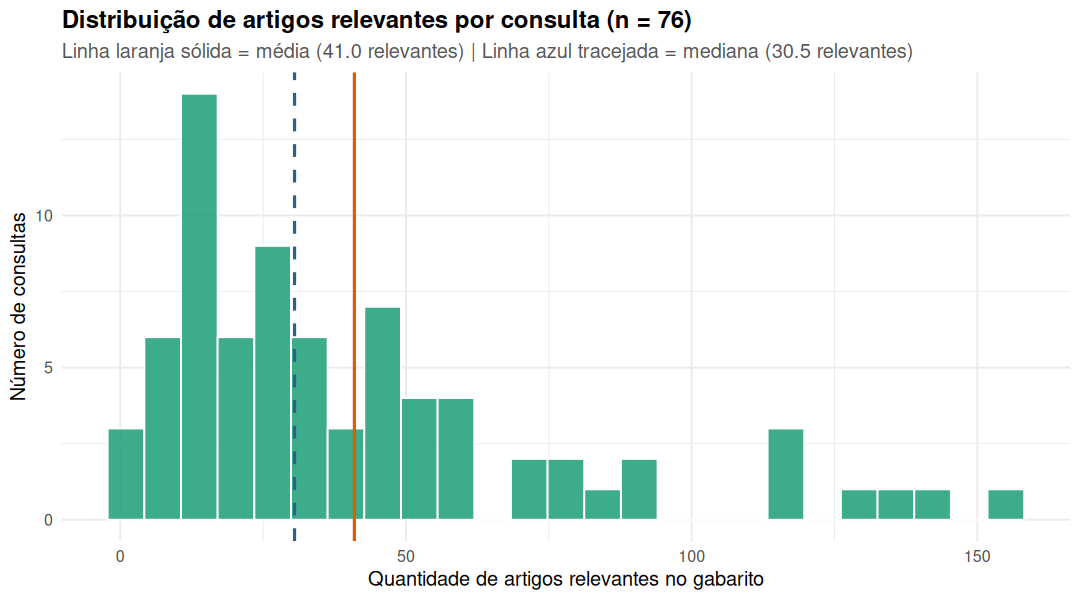

In [ ]:
# Gráfico 3: Distribuição de artigos relevantes por consulta
media_rel   <- mean(consultas_avaliadas$n_relevantes)
mediana_rel <- median(consultas_avaliadas$n_relevantes)

g_rel_consulta <- ggplot(consultas_avaliadas, aes(x = n_relevantes)) +
  geom_histogram(
    bins = 25,
    fill = CORES_PROJETO[["secundario"]],
    color = "white",
    alpha = 0.85
  ) +
  geom_vline(xintercept = mediana_rel, color = CORES_PROJETO[["principal"]], linetype = "dashed", linewidth = 0.9) +
  geom_vline(xintercept = media_rel,   color = CORES_PROJETO[["destaque"]],  linetype = "solid",  linewidth = 0.9) +
  labs(
    title = "Distribuição de artigos relevantes por consulta (n = 76)",
    subtitle = sprintf("Linha laranja sólida = média (%.1f relevantes) | Linha azul tracejada = mediana (%.1f relevantes)", media_rel, mediana_rel),
    x = "Quantidade de artigos relevantes no gabarito",
    y = "Número de consultas"
  )
print(g_rel_consulta)

# Extremos: 5 consultas com mais e 5 com menos relevantes
cat("Top 5 consultas com MAIS artigos relevantes:\n")
print(
  consultas_avaliadas %>%
    arrange(desc(n_relevantes)) %>%
    select(query_id, tipo, n_palavras, n_relevantes) %>%
    head(5)
)

cat("\nTop 5 consultas com MENOS artigos relevantes:\n")
print(
  consultas_avaliadas %>%
    arrange(n_relevantes) %>%
    select(query_id, tipo, n_palavras, n_relevantes) %>%
    head(5)
)

**Vocabulário predominante do acervo.** Para compreender o domínio temático dos documentos, listamos as 15 palavras mais frequentes nos 1.460 artigos (título + resumo), removendo apenas *stopwords* em inglês e tokens de um único caractere para evitar ruído nesta visualização exploratória. O pré-processamento completo com *stemming* de Porter é aplicado de forma unificada na seção 4.1.

     palavra frequencia
 information       1596
     library       1273
      system        770
   libraries        612
        data        601
    research        571
   retrieval        557
         use        526
     systems        496
     science        459
         one        457
  scientific        399
         can        391
        book        367
       study        362


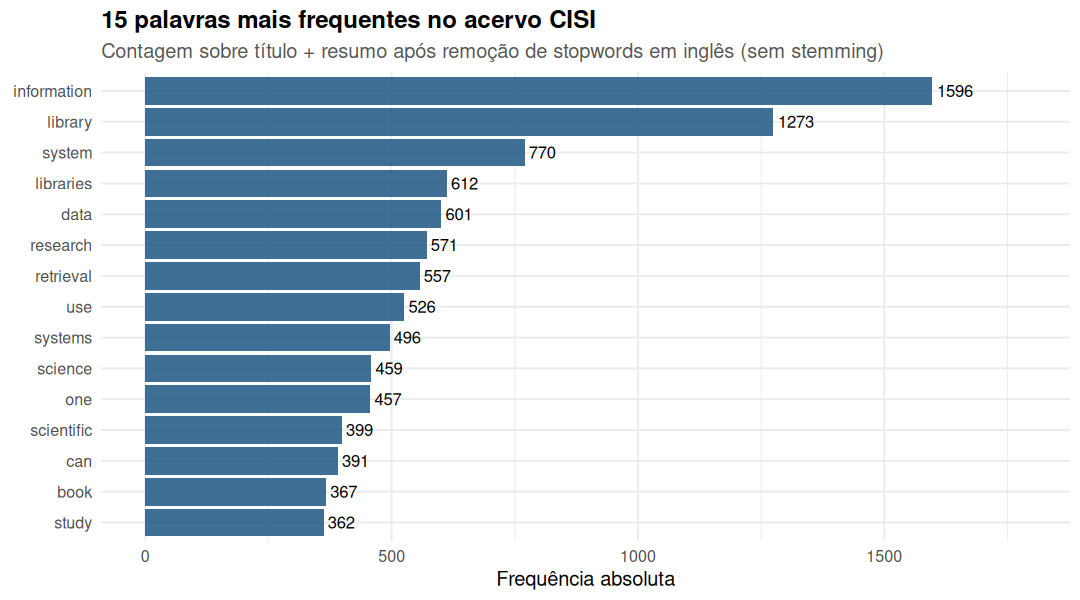

In [ ]:
# Extrai tokens dos artigos e remove stopwords em inglês apenas para esta visualização da EDA
sw_en <- stopwords::stopwords("en")
tokens_artigos <- unlist(lapply(artigos$texto, extrair_palavras), use.names = FALSE)
tokens_limpos  <- tokens_artigos[!(tokens_artigos %in% sw_en) & nchar(tokens_artigos) > 1L]

top_palavras <- as.data.frame(
  sort(table(tokens_limpos), decreasing = TRUE)[1:15],
  stringsAsFactors = FALSE
)
colnames(top_palavras) <- c("palavra", "frequencia")

print(top_palavras, row.names = FALSE)

# Gráfico 4: 15 palavras mais frequentes no acervo
g_top_palavras <- ggplot(top_palavras, aes(x = reorder(palavra, frequencia), y = frequencia)) +
  geom_col(fill = CORES_PROJETO[["principal"]], alpha = 0.9) +
  geom_text(aes(label = frequencia), hjust = -0.15, size = 3.5) +
  coord_flip() +
  expand_limits(y = max(top_palavras$frequencia) * 1.12) +
  labs(
    title = "15 palavras mais frequentes no acervo CISI",
    subtitle = "Contagem sobre título + resumo após remoção de stopwords em inglês (sem stemming)",
    x = NULL,
    y = "Frequência absoluta"
  )
print(g_top_palavras)

### 2.3. Análise Bivariada e Multivariada

Nesta seção, investigamos como as variáveis se relacionam entre si, conectando os achados diretamente à validação estatística (seção 3) e à motivação do BM25.

**Tamanho do artigo × Relevância.** Comparamos o comprimento (em palavras) dos artigos que são relevantes para pelo menos uma consulta com o dos artigos que nunca aparecem no gabarito. Além do *boxplot* com a média destacada, calculamos as correlações de Spearman e Pearson entre o tamanho do artigo e o número de consultas em que ele é relevante.

foi_relevante,n,media,mediana,dp,iqr,assimetria
<fct>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
Nunca relevante,298,125.51,117,57.65,76.5,0.71
Relevante,1162,127.74,119,65.25,77.8,1.53


Correlação (tamanho do artigo x nº de consultas em que é relevante): Spearman = 0.073 | Pearson = 0.119


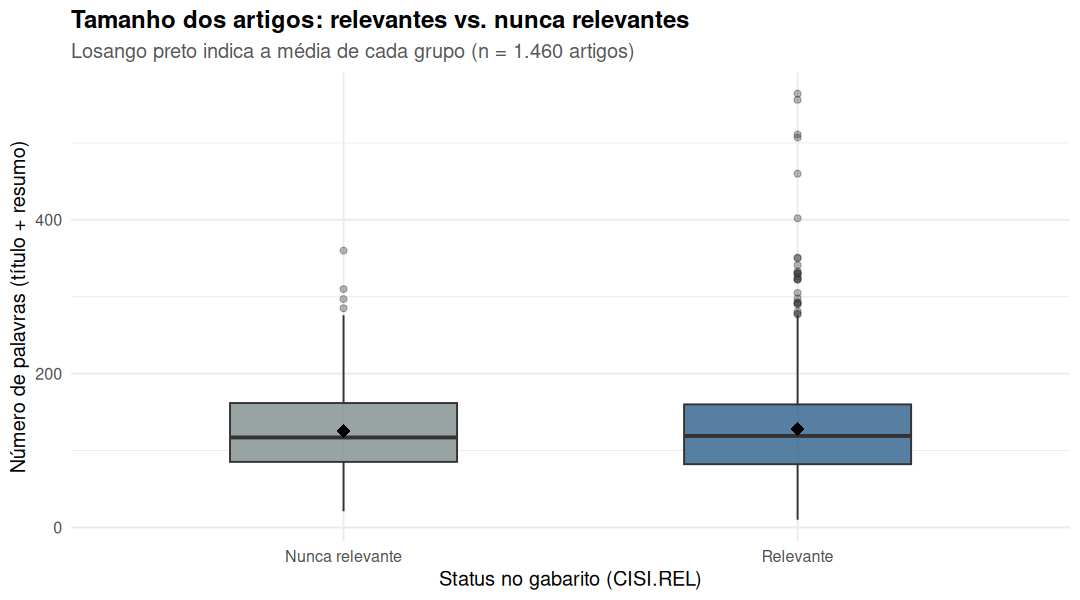

In [ ]:
# Estatísticas de tamanho separadas pelo status de relevância no gabarito
resumo_art_rel <- artigos %>%
  group_by(foi_relevante) %>%
  summarise(
    n          = n(),
    media      = round(mean(n_palavras), 2),
    mediana    = round(median(n_palavras), 1),
    dp         = round(sd(n_palavras), 2),
    iqr        = round(IQR(n_palavras), 1),
    assimetria = round(calcular_assimetria(n_palavras), 2),
    .groups    = "drop"
  )
resumo_art_rel

# Gráfico 5: Boxplot do tamanho dos artigos por status de relevância
g_art_rel <- ggplot(artigos, aes(x = foi_relevante, y = n_palavras, fill = foi_relevante)) +
  geom_boxplot(alpha = 0.8, outlier.alpha = 0.35, width = 0.5) +
  stat_summary(fun = mean, geom = "point", shape = 18, size = 3.5, color = "black") +
  scale_fill_manual(
    values = c("Nunca relevante" = CORES_PROJETO[["neutro"]],
               "Relevante"       = CORES_PROJETO[["principal"]])
  ) +
  labs(
    title = "Tamanho dos artigos: relevantes vs. nunca relevantes",
    subtitle = "Losango preto indica a média de cada grupo (n = 1.460 artigos)",
    x = "Status no gabarito (CISI.REL)",
    y = "Número de palavras (título + resumo)"
  ) +
  theme(legend.position = "none")
print(g_art_rel)

cor_art_sp <- cor(artigos$n_palavras, artigos$n_consultas_relevante, method = "spearman")
cor_art_pe <- cor(artigos$n_palavras, artigos$n_consultas_relevante, method = "pearson")
cat(sprintf(
  "Correlação (tamanho do artigo x nº de consultas em que é relevante): Spearman = %.3f | Pearson = %.3f\n",
  cor_art_sp, cor_art_pe
))

**Tipo de consulta × Tamanho e Número de relevantes.** Conforme identificado na limpeza (seção 2.1), as 76 consultas com gabarito dividem-se em 50 **perguntas** escritas por pesquisadores (`tipo == "pergunta"`) e 26 **resumos de artigos usados como consulta** (`tipo == "artigo"`). Comparamos os dois grupos quanto à extensão do texto e à quantidade de documentos relevantes no gabarito.

tipo_label,n_consultas,tam_media,tam_mediana,tam_iqr,rel_media,rel_mediana,rel_iqr
<fct>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
Pergunta,50,28.16,18.5,38.0,49.84,41.5,42.2
Artigo como consulta,26,120.54,101.5,57.2,23.92,14.0,22.5


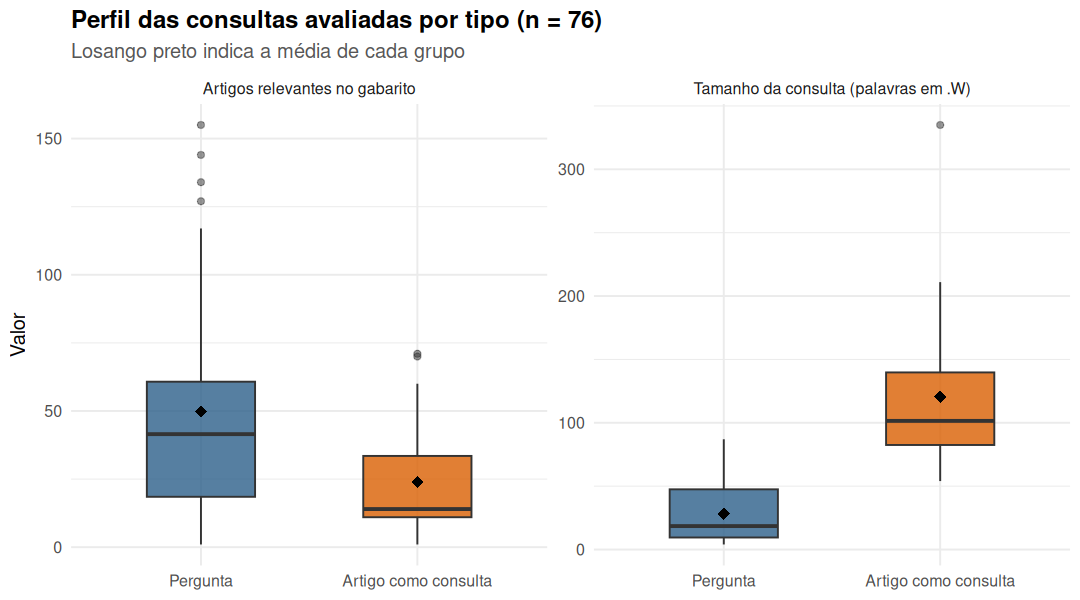

In [ ]:
# Cria rótulos legíveis para apresentação sem alterar a coluna original `tipo`
consultas_plot <- consultas_avaliadas %>%
  mutate(
    tipo_label = factor(
      tipo,
      levels = c("pergunta", "artigo"),
      labels = c("Pergunta", "Artigo como consulta")
    )
  )

# Tabela comparativa por tipo de consulta
resumo_tipo_qry <- consultas_plot %>%
  group_by(tipo_label) %>%
  summarise(
    n_consultas = n(),
    tam_media   = round(mean(n_palavras), 2),
    tam_mediana = round(median(n_palavras), 1),
    tam_iqr     = round(IQR(n_palavras), 1),
    rel_media   = round(mean(n_relevantes), 2),
    rel_mediana = round(median(n_relevantes), 1),
    rel_iqr     = round(IQR(n_relevantes), 1),
    .groups     = "drop"
  )
resumo_tipo_qry

# Gráfico 6: Comparação lado a lado de tamanho e nº de relevantes por tipo de consulta
consultas_long <- consultas_plot %>%
  select(query_id, tipo_label, n_palavras, n_relevantes) %>%
  pivot_longer(
    cols = c(n_palavras, n_relevantes),
    names_to = "metrica",
    values_to = "valor"
  ) %>%
  mutate(
    metrica = ifelse(
      metrica == "n_palavras",
      "Tamanho da consulta (palavras em .W)",
      "Artigos relevantes no gabarito"
    )
  )

g_tipo_qry <- ggplot(consultas_long, aes(x = tipo_label, y = valor, fill = tipo_label)) +
  geom_boxplot(alpha = 0.8, outlier.alpha = 0.5, width = 0.5) +
  stat_summary(fun = mean, geom = "point", shape = 18, size = 3.2, color = "black") +
  facet_wrap(~ metrica, scales = "free_y") +
  scale_fill_manual(
    values = c("Pergunta"             = CORES_PROJETO[["principal"]],
               "Artigo como consulta" = CORES_PROJETO[["destaque"]])
  ) +
  labs(
    title = "Perfil das consultas avaliadas por tipo (n = 76)",
    subtitle = "Losango preto indica a média de cada grupo",
    x = NULL,
    y = "Valor"
  ) +
  theme(legend.position = "none")
print(g_tipo_qry)

**Tamanho da consulta × Número de relevantes × Tipo de consulta (multivariada) e matriz de correlação dos artigos.** Verificamos conjuntamente se consultas mais longas tendem a ter mais artigos relevantes — separando a tendência por tipo de consulta para evitar confusão entre os dois perfis — e construímos um *heatmap* de correlação de Spearman para as variáveis numéricas dos 1.460 artigos.

Correlação global (tamanho da consulta x nº de relevantes): Spearman = -0.337 | Pearson = -0.165

Correlação estratificada por tipo de consulta:
# A tibble: 2 × 3
  tipo_label           spearman pearson
  <fct>                   <dbl>   <dbl>
1 Pergunta               -0.195  -0.02 
2 Artigo como consulta    0.231   0.529


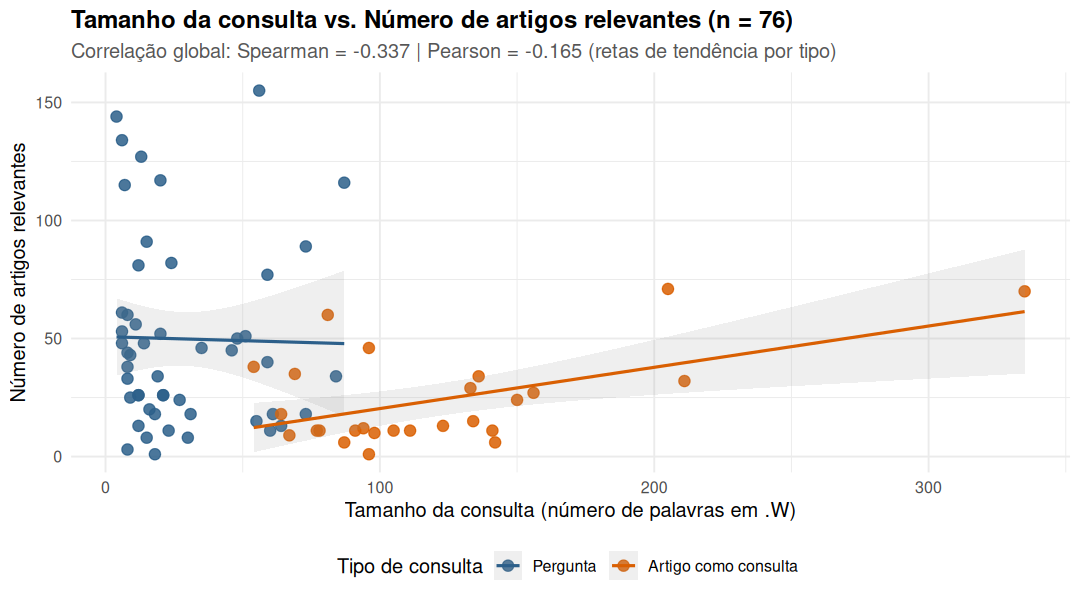

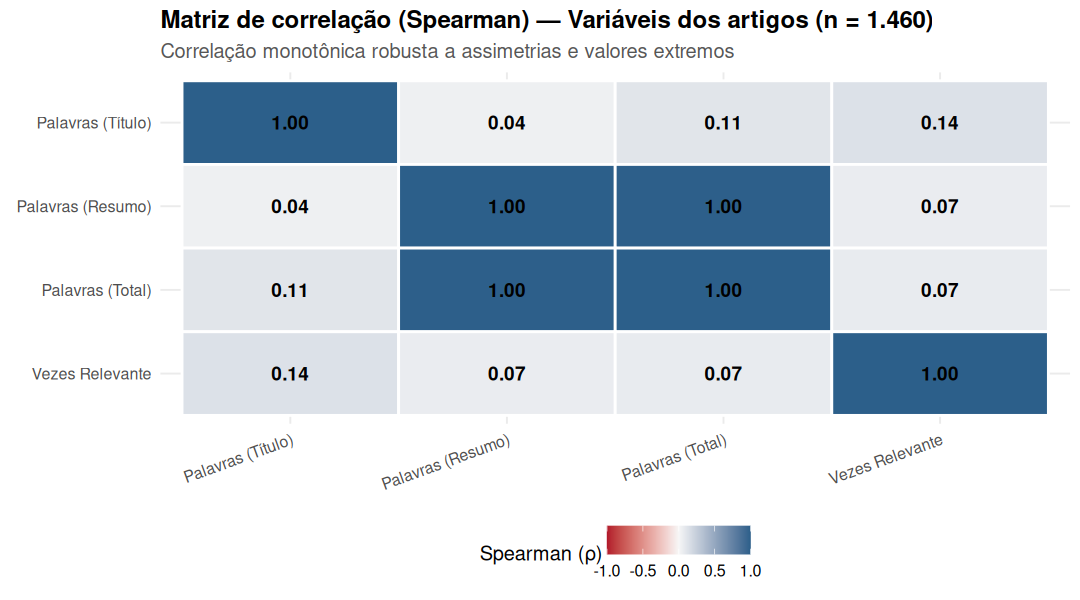

In [ ]:
# Correlação global e estratificada por tipo de consulta
cor_qry_sp <- cor(consultas_plot$n_palavras, consultas_plot$n_relevantes, method = "spearman")
cor_qry_pe <- cor(consultas_plot$n_palavras, consultas_plot$n_relevantes, method = "pearson")

cat(sprintf(
  "Correlação global (tamanho da consulta x nº de relevantes): Spearman = %.3f | Pearson = %.3f\n\n",
  cor_qry_sp, cor_qry_pe
))

cat("Correlação estratificada por tipo de consulta:\n")
print(
  consultas_plot %>%
    group_by(tipo_label) %>%
    summarise(
      spearman = round(cor(n_palavras, n_relevantes, method = "spearman"), 3),
      pearson  = round(cor(n_palavras, n_relevantes, method = "pearson"), 3),
      .groups  = "drop"
    )
)

# Gráfico 7: Dispersão (tamanho da consulta x relevantes, colorido por tipo)
g_scatter_qry <- ggplot(
  consultas_plot,
  aes(x = n_palavras, y = n_relevantes, color = tipo_label)
) +
  geom_point(size = 2.8, alpha = 0.85) +
  geom_smooth(method = "lm", formula = y ~ x, se = TRUE, alpha = 0.15, linewidth = 0.9) +
  scale_color_manual(
    values = c("Pergunta"             = CORES_PROJETO[["principal"]],
               "Artigo como consulta" = CORES_PROJETO[["destaque"]])
  ) +
  labs(
    title = "Tamanho da consulta vs. Número de artigos relevantes (n = 76)",
    subtitle = sprintf("Correlação global: Spearman = %.3f | Pearson = %.3f (retas de tendência por tipo)",
                       cor_qry_sp, cor_qry_pe),
    x = "Tamanho da consulta (número de palavras em .W)",
    y = "Número de artigos relevantes",
    color = "Tipo de consulta"
  )
print(g_scatter_qry)

# Gráfico 8: Heatmap de correlação de Spearman das variáveis numéricas dos artigos
vars_artigos <- artigos %>%
  select(
    `Palavras (Título)` = n_palavras_titulo,
    `Palavras (Resumo)` = n_palavras_resumo,
    `Palavras (Total)`  = n_palavras,
    `Vezes Relevante`   = n_consultas_relevante
  )

mat_cor <- cor(vars_artigos, method = "spearman")
df_cor <- as.data.frame(mat_cor) %>%
  mutate(var1 = rownames(mat_cor)) %>%
  pivot_longer(cols = -var1, names_to = "var2", values_to = "correlacao")

ordem_vars  <- colnames(mat_cor)
df_cor$var1 <- factor(df_cor$var1, levels = rev(ordem_vars))
df_cor$var2 <- factor(df_cor$var2, levels = ordem_vars)

g_heatmap <- ggplot(df_cor, aes(x = var2, y = var1, fill = correlacao)) +
  geom_tile(color = "white", linewidth = 0.8) +
  geom_text(aes(label = sprintf("%.2f", correlacao)), size = 4, fontface = "bold") +
  scale_fill_gradient2(
    low = "#B2182B",
    mid = "#F7F7F7",
    high = CORES_PROJETO[["principal"]],
    midpoint = 0,
    limits = c(-1, 1)
  ) +
  labs(
    title = "Matriz de correlação (Spearman) — Variáveis dos artigos (n = 1.460)",
    subtitle = "Correlação monotônica robusta a assimetrias e valores extremos",
    x = NULL,
    y = NULL,
    fill = "Spearman (ρ)"
  ) +
  theme(axis.text.x = element_text(angle = 20, hjust = 1))
print(g_heatmap)

### 2.4. Insights da EDA

A análise exploratória da coleção CISI trouxe evidências que conectam as características dos dados à validação estatística (seção 3) e à modelagem (seção 4):

1. **O gabarito cobre a maior parte do acervo:** dos 1.460 artigos, 1.162 (79,6%) aparecem como relevantes em pelo menos uma das 76 consultas avaliadas, e 298 (20,4%) nunca são marcados como relevantes.
2. **Os artigos têm tamanhos bem diferentes:** o tamanho (título + resumo) varia de 10 a 564 palavras (média = 127,3, mediana = 118,5, IQR = 77,2), com assimetria positiva de 1,41: a maioria dos artigos é curta, e alguns poucos são muito longos. Um modelo que favorece documentos longos pode distorcer o ranking, e é justamente isso que o parâmetro *b* do BM25 corrige.
3. **Os dois tipos de consulta são bem diferentes (desvio do Projeto 1):** as 50 **perguntas** têm mediana de 18,5 palavras e 41,5 artigos relevantes, enquanto os 26 **artigos usados como consulta** têm mediana de 102 palavras e 14 relevantes. Ou seja, as consultas do tipo artigo são cerca de 5 vezes mais longas e têm cerca de 3 vezes menos relevantes. Usamos o campo `.W` em todas e, na seção 5.2, verificamos se o BM25 se comporta de forma diferente nos dois tipos.
4. **A quantidade de relevantes varia muito de uma consulta para outra:** de 1 a 155 artigos relevantes por consulta (mediana = 30,5, média = 41,0). Consultas com muitos relevantes tendem a ter notas mais altas em qualquer modelo. Por isso, a comparação entre os modelos é feita consulta a consulta, com o **teste t pareado** (seção 5), que cancela essa diferença de dificuldade.
5. **O tamanho do artigo quase não muda entre relevantes e não relevantes:** os artigos relevantes têm média de 127,7 palavras (mediana = 119, assimetria = 1,53), e os nunca relevantes, média de 125,5 palavras (mediana = 117, assimetria = 0,71). A correlação entre o tamanho do artigo e o número de consultas em que ele é relevante também é fraca (Spearman = 0,07). Na seção 3, testamos formalmente se essa diferença é estatisticamente significativa.


## 3. Validação Estatística (Teste de Hipóteses)

### 3.1. Definição das Hipóteses

A EDA compara o tamanho dos artigos (número de palavras no título + resumo) entre os que aparecem como relevantes no gabarito e os que nunca aparecem. Como as distribuições são assimétricas — assimetria de **0,71** nos 298 artigos nunca relevantes e de **1,53** nos 1.162 relevantes — aplicaremos o teste de Mann–Whitney, conforme a alternativa prevista em `docs/PROJETO.md`.

Para manter as hipóteses compatíveis com esse teste, comparamos as distribuições dos tamanhos:

- **H_0:** a distribuição do tamanho dos artigos é igual nos dois grupos.
- **H_a:** as distribuições do tamanho dos artigos diferem entre os grupos.

O teste é bilateral, com nível de significância **α = 0,05**. Essa formulação testa uma diferença de distribuição (interpretável como deslocamento de localização quando as formas são semelhantes), não uma diferença de médias. O resultado indica associação entre tamanho e relevância no CISI, não causalidade.


### 3.2. Escolha e Execução do Teste

Os grupos são independentes: cada artigo pertence a apenas uma das categorias. Como a assimetria observada, sobretudo entre os relevantes, desaconselha tratar os tamanhos como aproximadamente normais, usamos o teste de Mann–Whitney (Wilcoxon para amostras independentes), em vez do teste t de Welch planejado como alternativa padrão. O teste não exige normalidade.

O tamanho é uma contagem inteira, portanto há empates. `exact = FALSE` solicita a aproximação normal com correção de continuidade, apropriada para calcular o p-valor nesse caso. A tabela abaixo apresenta estatísticas descritivas dos grupos; o teste compara suas distribuições.


In [ ]:
# Compara o tamanho dos artigos entre os dois grupos independentes.
# Entrada: `artigos`, com tamanho e status de relevância. Saída: resumo descritivo e teste de Mann–Whitney.
stopifnot(!anyNA(artigos$n_palavras), !anyNA(artigos$foi_relevante))
grupos_tamanho <- split(artigos$n_palavras, artigos$foi_relevante)
stopifnot(identical(names(grupos_tamanho), c("Nunca relevante", "Relevante")))

resumo_tamanho <- data.frame(
  grupo      = names(grupos_tamanho),
  n          = vapply(grupos_tamanho, length, integer(1)),
  media      = round(vapply(grupos_tamanho, mean, numeric(1)), 2),
  mediana    = vapply(grupos_tamanho, median, numeric(1)),
  assimetria = round(vapply(grupos_tamanho, calcular_assimetria, numeric(1)), 2),
  row.names  = NULL
)
resumo_tamanho

teste_mann_whitney <- stats::wilcox.test(
  x = grupos_tamanho[["Relevante"]],
  y = grupos_tamanho[["Nunca relevante"]],
  alternative = "two.sided",
  exact = FALSE,
  correct = TRUE
)
teste_mann_whitney


### 3.3. Interpretação do p-valor

Comparamos o p-valor com **α = 0,05**. Se `p < 0,05`, rejeitamos H₀ e concluímos que há evidência de diferença entre as distribuições de tamanho; caso contrário, não rejeitamos H₀, o que não prova que elas sejam iguais. Em ambos os casos, a conclusão se refere à associação observada nesta coleção, não a um efeito causal.

A célula seguinte aplica essa regra ao resultado do teste e mostra as medianas apenas como descrição dos grupos.


In [ ]:
# Interpreta o p-valor conforme o nível de significância definido.
# Entrada: resultado do teste e resumo dos grupos. Saída: decisão estatística e medianas descritivas.
alpha_teste <- 0.05
p_teste <- teste_mann_whitney$p.value
mediana_nunca_relevante <- resumo_tamanho$mediana[resumo_tamanho$grupo == "Nunca relevante"]
mediana_relevante <- resumo_tamanho$mediana[resumo_tamanho$grupo == "Relevante"]

cat(sprintf("p-valor = %s; α = %.2f.\n", format.pval(p_teste, digits = 4), alpha_teste))
if (p_teste < alpha_teste) {
  cat("Rejeitamos H₀: há evidência estatística de que as distribuições dos tamanhos diferem.\n")
} else {
  cat("Não rejeitamos H₀: não há evidência estatística suficiente de diferença entre as distribuições dos tamanhos.\n")
}
cat(sprintf(
  "Medianas amostrais (nunca relevante; relevante): %g e %g palavras; são descritivas e não indicam causalidade.\n",
  mediana_nunca_relevante, mediana_relevante
))


**Resultado:** o p-valor (≈ 0,97) é muito maior que α = 0,05, então **não rejeitamos H₀**. Não há evidência de que o tamanho dos artigos relevantes seja diferente do tamanho dos artigos nunca relevantes: as medianas (119 e 117 palavras) são praticamente iguais.

**O que isso significa para o projeto:** no CISI, **ser longo não torna um artigo mais relevante**. Então, se um modelo de busca dá notas maiores a artigos longos só por terem mais palavras, ele está criando um viés que não corresponde à relevância real. O mesmo vale no sentido contrário: favorecer artigos curtos também é um viés. Os dois modelos tratam o tamanho de formas diferentes. O TF-IDF com cosseno divide pelo tamanho do vetor do artigo, o que na prática tende a favorecer artigos curtos (Singhal, Buckley e Mitra, 1996). Já o BM25 compara o tamanho do artigo com o tamanho médio da coleção, com intensidade controlada pelo parâmetro *b*, e ainda satura a frequência dos termos (parâmetro *k1*). Como o tamanho não está associado à relevância, o modelo que lidar melhor com essas diferenças deve ranquear melhor, e é isso que testamos nas seções 4 e 5.


## 4. Pré-processamento e Aplicação da Técnica

### 4.1. Preparação dos Dados para o Modelo

Antes de aplicar qualquer modelo de recuperação de informação, os textos precisam
passar por uma **cadeia de pré-processamento comum**: a mesma função é aplicada aos
artigos e às consultas, para os dois modelos. Se cada modelo recebesse o texto de forma
diferente, não seria possível saber se uma diferença de desempenho veio do modelo ou
do tratamento do texto.

A cadeia tem quatro passos:

1. **Minúsculas** — elimina distinção entre `Information` e `information`.
2. **Tokenização** — separa o texto em palavras formadas apenas por letras (`[a-z]+`);
   pontuação, números e símbolos são descartados.
3. **Remoção de *stopwords*** — palavras de alta frequência mas baixo conteúdo semântico
   (`the`, `of`, `and` …) são removidas com a lista em inglês do pacote `stopwords`.
4. **Stemming de Porter** — reduz cada palavra à sua raiz morfológica
   (`retrieval → retriev`, `systems → system`) com o pacote `SnowballC`.
   Reduz a esparsidade do vocabulário e faz com que formas flexionadas da mesma palavra
   sejam tratadas como iguais.

Ao final, cada texto vira um **vetor de tokens** (raízes de palavras com conteúdo semântico),
que é a entrada comum para TF-IDF e BM25.

In [ ]:
# Pipeline de pré-processamento — aplicado igualmente a artigos e consultas.
# Entrada: texto (string). Saída: vetor de raízes de palavras (tokens).
sw_en <- stopwords::stopwords("en", source = "snowball")

preprocessar <- function(texto) {
  if (is.na(texto) || !nzchar(trimws(texto))) return(character(0))
  tokens <- extrair_palavras(texto)                 # 1. minúsculas + tokenização
  tokens <- tokens[!tokens %in% sw_en]              # 2. remove stopwords
  SnowballC::wordStem(tokens, language = "english") # 3. stemming de Porter
}

# Aplica o pré-processamento a todos os artigos e consultas avaliadas.
# Resulta em listas nomeadas de vetores de tokens.
tokens_artigos   <- setNames(lapply(artigos$texto,            preprocessar), artigos$doc_id)
tokens_consultas <- setNames(lapply(consultas_avaliadas$texto, preprocessar), consultas_avaliadas$query_id)

# Verificação: contagens pós-pré-processamento
n_tokens_artigos   <- vapply(tokens_artigos,   length, integer(1))
n_tokens_consultas <- vapply(tokens_consultas, length, integer(1))

cat(sprintf(
  "Artigos:   %d documentos | média %.0f tokens | mín %d | máx %d\n",
  length(tokens_artigos), mean(n_tokens_artigos), min(n_tokens_artigos), max(n_tokens_artigos)
))
cat(sprintf(
  "Consultas: %d documentos | média %.0f tokens | mín %d | máx %d\n",
  length(tokens_consultas), mean(n_tokens_consultas), min(n_tokens_consultas), max(n_tokens_consultas)
))

# Vocabulário compartilhado (união de todos os tokens únicos dos artigos)
vocabulario <- sort(unique(unlist(tokens_artigos)))
cat(sprintf("Vocabulário do acervo (após pré-processamento): %d termos únicos\n", length(vocabulario)))

### 4.2. Modelagem

Com os tokens em mãos, aplicamos os dois modelos de ranqueamento.
Ambos recebem os mesmos tokens; a diferença está na fórmula de pontuação.

---

#### TF-IDF com similaridade do cosseno

O **TF-IDF** representa cada documento e cada consulta como um vetor de pesos no espaço do vocabulário.
O peso de um termo $t$ no documento $d$ é:

$$w(t, d) = \text{tf}(t,d) \times \text{idf}(t)$$

onde $\text{tf}(t,d)$ é o número de ocorrências de $t$ em $d$ e

$$\text{idf}(t) = \log_{10}\!\left(\frac{N}{\text{df}(t)}\right)$$

sendo $N = 1\,460$ o total de artigos e $\text{df}(t)$ o número de artigos que contêm $t$.

A nota de um artigo para uma consulta é o **cosseno** entre os dois vetores. Dividir pelo tamanho
dos vetores evita que artigos longos ganhem pontos só por terem mais palavras, mas, na prática,
tende a favorecer artigos curtos:

$$\text{score}_{\text{TF-IDF}}(d, q) = \frac{\vec{d} \cdot \vec{q}}{\|\vec{d}\| \cdot \|\vec{q}\|}$$

---

#### BM25 (Okapi BM25)

O **BM25** é um modelo probabilístico que satura a contribuição de um termo e normaliza
explicitamente pelo comprimento do documento:

$$\text{score}_{\text{BM25}}(d, q) = \sum_{t \in q} \text{idf}(t) \cdot
\frac{f(t,d)\,(k_1+1)}{f(t,d) + k_1\!\left(1 - b + b\,\frac{|d|}{\overline{dl}}\right)}$$

onde $f(t,d)$ é a frequência do termo no documento, $|d|$ é o tamanho do documento em tokens,
$\overline{dl}$ é o tamanho médio dos artigos, e os parâmetros são os valores padrão da
literatura: **$k_1 = 1{,}2$** (saturação) e **$b = 0{,}75$** (normalização pelo tamanho).

Nos dois modelos usamos o **mesmo idf**, $\log_{10}(N/\text{df}(t))$, e um termo repetido na consulta
conta uma vez para cada ocorrência. Assim, a diferença entre os modelos vem só da forma de pontuar.
Termos da consulta que não aparecem em nenhum artigo são ignorados.

**Por que parâmetros padrão?** Ajustar $k_1$ e $b$ nas mesmas 76 consultas da avaliação
daria uma vantagem injusta ao BM25 (overfitting ao conjunto de teste). Os valores
$k_1 = 1{,}2$ e $b = 0{,}75$ são consagrados na literatura de recuperação de informação.

In [ ]:
# ── Estruturas auxiliares ──────────────────────────────────────────────────────
# Frequência de cada termo em cada artigo: lista de tabelas nomeadas.
# Entrada: tokens_artigos. Saída: lista com uma tabela de frequências por artigo.
freq_artigos <- lapply(tokens_artigos, table)

# Frequência de documentos (df): em quantos artigos cada termo aparece.
# Entrada: tokens_artigos. Saída: vetor inteiro nomeado pelo termo.
N_docs    <- length(tokens_artigos)
df_termos <- table(unlist(lapply(tokens_artigos, unique), use.names = FALSE))
df_termos <- setNames(as.integer(df_termos), names(df_termos))[vocabulario]

# IDF = log10(N / df). Todo termo do vocabulário aparece em pelo menos um artigo (df >= 1).
# Entrada: df_termos e N_docs. Saída: vetor numérico nomeado pelo termo.
idf_termos <- log10(N_docs / df_termos)

# Tamanho de cada artigo em tokens e comprimento médio (usados pelo BM25).
dl_artigos <- vapply(tokens_artigos, length, integer(1))
avgdl      <- mean(dl_artigos)

# Norma do vetor TF-IDF de cada artigo (usada no cosseno). Calculada uma vez só.
# Entrada: freq_artigos e idf_termos. Saída: vetor numérico nomeado pelo doc_id.
norma_artigos <- vapply(freq_artigos, function(f) {
  sqrt(sum((as.numeric(f) * idf_termos[names(f)])^2))
}, numeric(1))

# Frequência dos termos de cada consulta, só com termos que existem no acervo.
# Entrada: tokens_consultas. Saída: lista com uma tabela de frequências por consulta.
freq_consultas <- lapply(tokens_consultas, function(tq) {
  f <- table(tq)
  f[names(f) %in% vocabulario]
})

cat(sprintf("N = %d artigos | tamanho médio = %.1f tokens | termos de consulta fora do acervo: %d\n",
            N_docs, avgdl,
            sum(vapply(tokens_consultas, function(tq) sum(!tq %in% vocabulario), integer(1)))))


In [ ]:
# ── TF-IDF: ranqueamento por similaridade do cosseno ──────────────────────────
# Calcula a nota TF-IDF de um artigo para uma consulta.
# Entrada: frequências da consulta (freq_q), frequências do artigo (freq_d), idf dos termos
#          e as normas dos dois vetores. Saída: similaridade do cosseno (escalar numérico).
score_tfidf <- function(freq_q, freq_d, idf, norma_q, norma_d) {
  termos_comuns <- intersect(names(freq_d), names(freq_q))
  if (length(termos_comuns) == 0L || norma_q == 0 || norma_d == 0) return(0)
  w_d <- as.numeric(freq_d[termos_comuns]) * idf[termos_comuns]
  w_q <- as.numeric(freq_q[termos_comuns]) * idf[termos_comuns]
  sum(w_d * w_q) / (norma_d * norma_q)
}

# Gera o ranking completo (todos os 1.460 artigos) para cada uma das 76 consultas.
# Saída: data frame com colunas query_id, doc_id, score, rank_tfidf.
ranking_tfidf <- do.call(rbind, lapply(names(freq_consultas), function(qid) {
  fq      <- freq_consultas[[qid]]
  norma_q <- sqrt(sum((as.numeric(fq) * idf_termos[names(fq)])^2))
  notas <- vapply(names(freq_artigos), function(did) {
    score_tfidf(fq, freq_artigos[[did]], idf_termos, norma_q, norma_artigos[[did]])
  }, numeric(1))
  ordem <- order(notas, decreasing = TRUE)
  data.frame(
    query_id   = as.integer(qid),
    doc_id     = as.integer(names(notas)[ordem]),
    score      = unname(notas[ordem]),
    rank_tfidf = seq_along(ordem)
  )
}))

stopifnot(nrow(ranking_tfidf) == 76L * N_docs, !anyNA(ranking_tfidf$score))
cat(sprintf("TF-IDF concluído: %d linhas (76 consultas × %d artigos).\n", nrow(ranking_tfidf), N_docs))


In [ ]:
# ── BM25: ranqueamento probabilístico ─────────────────────────────────────────
# Parâmetros BM25 (valores padrão da literatura — ver seção 4.2 e PROJETO.md).
k1_bm25 <- 1.2
b_bm25  <- 0.75

# Calcula o score BM25 de um artigo para uma consulta.
# Entrada: frequências da consulta (freq_q) e do artigo (freq_d), idf dos termos,
#          tamanho do artigo (dl), tamanho médio (avgdl), k1 e b.
# Saída: score BM25 (escalar numérico). Termos repetidos na consulta contam uma vez por ocorrência.
score_bm25 <- function(freq_q, freq_d, idf, dl, avgdl, k1, b) {
  termos_comuns <- intersect(names(freq_d), names(freq_q))
  if (length(termos_comuns) == 0L) return(0)
  f_td  <- as.numeric(freq_d[termos_comuns])
  q_t   <- as.numeric(freq_q[termos_comuns])
  idf_t <- idf[termos_comuns]
  norm  <- 1 - b + b * dl / avgdl
  sum(q_t * idf_t * f_td * (k1 + 1) / (f_td + k1 * norm))
}

# Gera o ranking completo para cada uma das 76 consultas.
# Saída: data frame com colunas query_id, doc_id, score, rank_bm25.
ranking_bm25 <- do.call(rbind, lapply(names(freq_consultas), function(qid) {
  fq    <- freq_consultas[[qid]]
  notas <- vapply(names(freq_artigos), function(did) {
    score_bm25(fq, freq_artigos[[did]], idf_termos, dl_artigos[[did]], avgdl, k1_bm25, b_bm25)
  }, numeric(1))
  ordem <- order(notas, decreasing = TRUE)
  data.frame(
    query_id  = as.integer(qid),
    doc_id    = as.integer(names(notas)[ordem]),
    score     = unname(notas[ordem]),
    rank_bm25 = seq_along(ordem)
  )
}))

stopifnot(nrow(ranking_bm25) == 76L * N_docs, !anyNA(ranking_bm25$score))
cat(sprintf("BM25 concluído: %d linhas (76 consultas × %d artigos).\n", nrow(ranking_bm25), N_docs))


In [ ]:
# ── Funções de métricas ────────────────────────────────────────────────────────
# As métricas são calculadas por consulta, com relevância binária.

# P@k: fração de relevantes entre os k primeiros documentos do ranking.
# Entrada: vetor de relevância (0/1) ordenado pelo ranking, inteiro k.
# Saída: escalar numérico em [0, 1].
precisao_em_k <- function(relevancia_ordenada, k = 10L) {
  k <- min(k, length(relevancia_ordenada))
  if (k == 0L) return(0)
  sum(relevancia_ordenada[seq_len(k)]) / k
}

# AP (Average Precision): média das precisões medidas em cada posição onde
# aparece um relevante. Relevantes nunca recuperados contam como precisão 0.
# Entrada: vetor de relevância (0/1) ordenado pelo ranking, total de relevantes.
# Saída: escalar numérico em [0, 1].
average_precision <- function(relevancia_ordenada, n_relevantes) {
  if (n_relevantes == 0L) return(NA_real_)
  acumulado <- cumsum(relevancia_ordenada)
  posicoes  <- seq_along(relevancia_ordenada)
  precisoes <- ifelse(relevancia_ordenada == 1L, acumulado / posicoes, 0)
  sum(precisoes) / n_relevantes
}

# nDCG@k: Normalized Discounted Cumulative Gain com ganho binário (1/0).
# A ordem ideal coloca TODOS os relevantes da consulta no topo (até k deles),
# e não só os relevantes que o modelo trouxe nos k primeiros.
# Entrada: vetor de relevância (0/1) ordenado pelo ranking, total de relevantes, inteiro k.
# Saída: escalar numérico em [0, 1].
ndcg_em_k <- function(relevancia_ordenada, n_relevantes, k = 10L) {
  k    <- min(k, length(relevancia_ordenada))
  rel  <- relevancia_ordenada[seq_len(k)]
  dcg  <- sum(rel / log2(seq_len(k) + 1))
  n_ideal <- min(n_relevantes, k)
  if (n_ideal == 0L) return(NA_real_)
  idcg <- sum(1 / log2(seq_len(n_ideal) + 1))
  dcg / idcg
}

# ── Conferência manual obrigatória da AP (exigida pelo PROJETO.md) ────────────
# Lista de referência: [relevante, irrelevante, relevante, irrelevante, irrelevante, relevante]
# Total de relevantes na coleção: 3. AP esperada ≈ 0,722.
rel_exemplo  <- c(1, 0, 1, 0, 0, 1)
ap_conferida <- average_precision(rel_exemplo, n_relevantes = 3L)
ap_esperada  <- (1/1 + 2/3 + 3/6) / 3

cat(sprintf(
  "Conferência da AP:\n  Calculada: %.4f\n  Esperada:  %.4f\n  OK: %s\n",
  ap_conferida, ap_esperada,
  ifelse(abs(ap_conferida - ap_esperada) < 1e-6, "SIM ✓", "FALHOU ✗")
))
stopifnot(abs(ap_conferida - ap_esperada) < 1e-6)

# ── Conferência manual do nDCG@10 ─────────────────────────────────────────────
# Lista [irrelevante, relevante, irrelevante, ...] com 3 relevantes no total:
# DCG = 1/log2(3); ordem ideal = 3 relevantes no topo: IDCG = 1/log2(2) + 1/log2(3) + 1/log2(4).
rel_exemplo_ndcg <- c(0, 1, rep(0, 8))
ndcg_conferido   <- ndcg_em_k(rel_exemplo_ndcg, n_relevantes = 3L)
ndcg_esperado    <- (1 / log2(3)) / (1 / log2(2) + 1 / log2(3) + 1 / log2(4))

cat(sprintf(
  "Conferência do nDCG@10:\n  Calculado: %.4f\n  Esperado:  %.4f\n  OK: %s\n",
  ndcg_conferido, ndcg_esperado,
  ifelse(abs(ndcg_conferido - ndcg_esperado) < 1e-6, "SIM ✓", "FALHOU ✗")
))
stopifnot(abs(ndcg_conferido - ndcg_esperado) < 1e-6)

In [ ]:
# ── Amostra dos rankings das 5 primeiras consultas ────────────────────────────
# Junta os rankings com o gabarito para verificar visualmente.
# Entrada: ranking_tfidf, ranking_bm25, gabarito. Saída: tabela comparativa.
head_rankings <- function(ranking, col_rank, n_consultas = 5L, n_top = 5L) {
  ids_consultas <- sort(unique(ranking$query_id))[seq_len(n_consultas)]
  do.call(rbind, lapply(ids_consultas, function(qid) {
    top <- ranking[ranking$query_id == qid, ][seq_len(n_top), ]
    rel <- gabarito$doc_id[gabarito$query_id == qid]
    top$relevante <- as.integer(top$doc_id %in% rel)
    top[, c("query_id", col_rank, "doc_id", "relevante", "score")]
  }))
}

cat("--- Top-5 TF-IDF (5 primeiras consultas) ---\n")
print(head_rankings(ranking_tfidf, "rank_tfidf"))

cat("\n--- Top-5 BM25 (5 primeiras consultas) ---\n")
print(head_rankings(ranking_bm25,  "rank_bm25"))

## 5. Resultados e Interpretação

### 5.1. Apresentação dos Resultados

*A preencher.*

### 5.2. Análise Crítica dos Resultados

*A preencher.*

## 6. Conclusão

### 6.1. Resumo dos Insights

*A preencher.*

### 6.2. Recomendações Práticas

*A preencher.*

### 6.3. Limitações e Próximos Passos

*A preencher.*

## Referências

*A preencher.*